In [44]:
# Load data and create splits

In [45]:
import pandas as pd
import numpy as np

# Load engineered dataset
df = pd.read_csv(
    "../data/processed/iex_dam_2025_features.csv",
    parse_dates=["timestamp"]
)

# Chronological split
train_df = df[df["timestamp"] < "2025-10-01"].copy()

val_df = df[
    (df["timestamp"] >= "2025-10-01") &
    (df["timestamp"] < "2025-12-01")
].copy()

test_df = df[df["timestamp"] >= "2025-12-01"].copy()

print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Testing records:", len(test_df))

Training records: 25441
Validation records: 5856
Testing records: 2976


In [46]:
# Train Random Forest

In [47]:
import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Define features
feature_columns = [
    "time_slot",
    "is_weekend",
    "time_sin",
    "time_cos",
    "dow_sin",
    "dow_cos",
    "month_sin",
    "month_cos",
    "lag_1_day",
    "lag_7_days",
    "rolling_7d_mean",
    "rolling_7d_std"
]

target = "price_inr_mwh"

# Training data
X_train = train_df[feature_columns]
y_train = train_df[target]

# Validation data
X_val = val_df[feature_columns]
y_val = val_df[target]

# Initialize model
rf_model = RandomForestRegressor(
    n_estimators=10,
    max_depth=6,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train
rf_model.fit(X_train, y_train)

# Predict
rf_predictions = rf_model.predict(X_val)

# Evaluate
mae = mean_absolute_error(y_val, rf_predictions)
rmse = np.sqrt(mean_squared_error(y_val, rf_predictions))

print("Random Forest Validation Results")
print(f"MAE:  ₹{mae:.2f}/MWh")
print(f"RMSE: ₹{rmse:.2f}/MWh")

Random Forest Validation Results
MAE:  ₹489.88/MWh
RMSE: ₹830.76/MWh


In [48]:
results = []

for name, predictions in [
    ("Previous Day", val_df["lag_1_day"]),
    ("Previous Week", val_df["lag_7_days"]),
    ("Random Forest", rf_predictions)
]:
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_val, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_val, predictions))
    })

results_df = pd.DataFrame(results)

display(results_df.round(2))

,Model,MAE,RMSE
0,Previous Day,523.16,1042.98
1,Previous Week,755.58,1268.60
2,Random Forest,489.88,830.76


,Feature,Importance
8,lag_1_day,0.874910
5,dow_cos,0.045417
9,lag_7_days,0.028060
1,is_weekend,0.014154
4,dow_sin,0.012082
0,time_slot,0.011003
10,rolling_7d_mean,0.003974
6,month_sin,0.003154
2,time_sin,0.003024
11,rolling_7d_std,0.002868


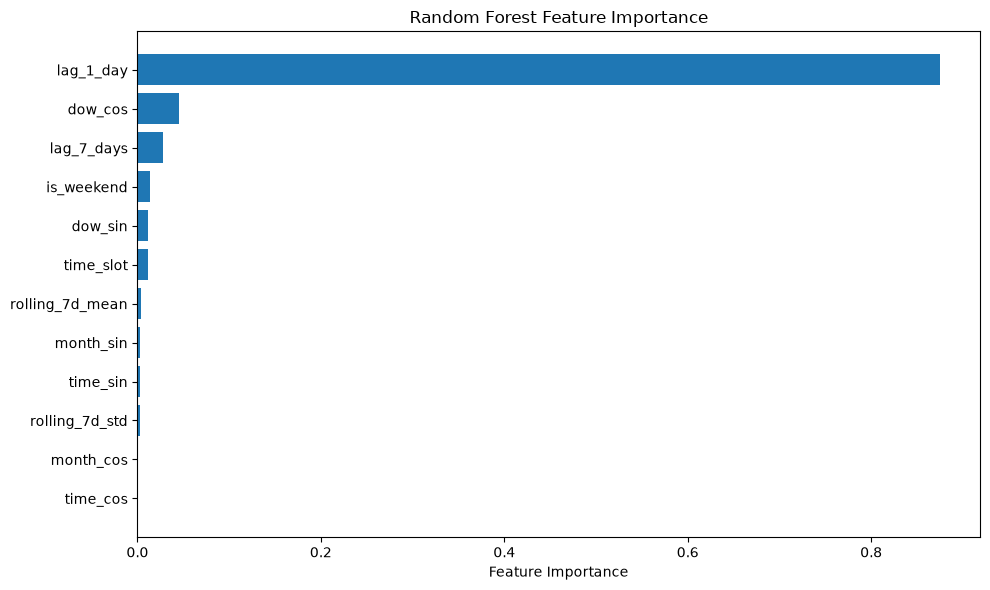

In [49]:
import pandas as pd
import matplotlib.pyplot as plt

importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df)

plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Feature Importance")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [50]:
# Create a results dataframe
error_df = val_df[["timestamp", "price_inr_mwh"]].copy()

error_df["prediction"] = rf_predictions

error_df["error"] = (
    error_df["price_inr_mwh"] - error_df["prediction"]
)

error_df["absolute_error"] = error_df["error"].abs()

error_df["hour"] = error_df["timestamp"].dt.hour

# Calculate hourly errors
hourly_errors = error_df.groupby("hour").agg(
    MAE=("absolute_error", "mean"),
    RMSE=("error", lambda x: np.sqrt((x ** 2).mean()))
)

display(hourly_errors.round(2))

,MAE,RMSE
hour,,
0,371.19,566.20
1,398.23,549.28
2,363.73,483.32
3,345.33,495.52
4,355.92,504.73
5,325.93,475.78
6,341.00,458.02
7,340.36,443.49
8,492.77,654.17


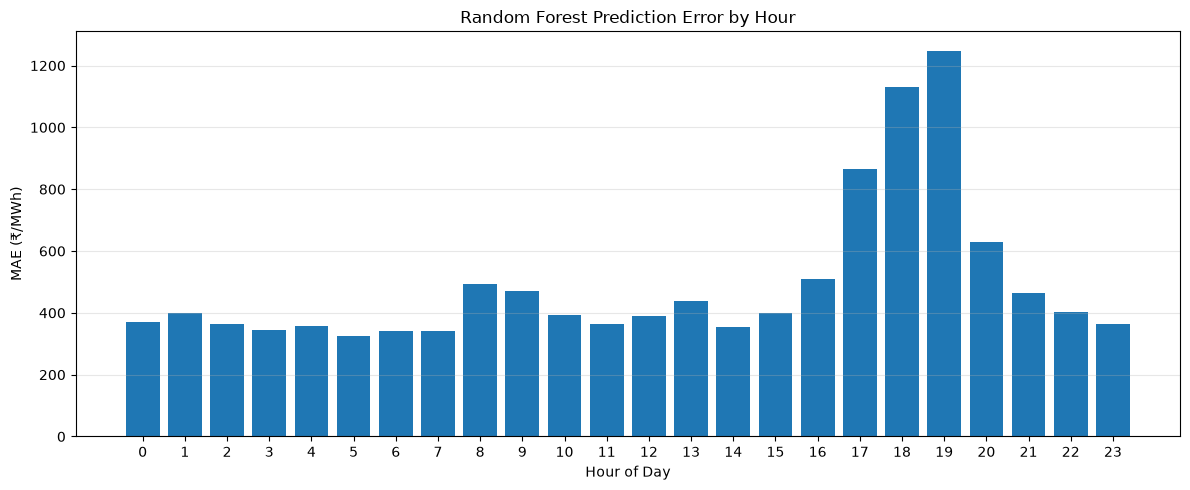

In [51]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.bar(
    hourly_errors.index,
    hourly_errors["MAE"]
)

plt.xlabel("Hour of Day")
plt.ylabel("MAE (₹/MWh)")
plt.title("Random Forest Prediction Error by Hour")

plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [52]:
comparison_df = val_df[
    ["timestamp", "price_inr_mwh", "lag_1_day"]
].copy()

comparison_df["rf_prediction"] = rf_predictions

comparison_df["hour"] = comparison_df["timestamp"].dt.hour

comparison_df["baseline_error"] = (
    comparison_df["price_inr_mwh"] -
    comparison_df["lag_1_day"]
)

comparison_df["rf_error"] = (
    comparison_df["price_inr_mwh"] -
    comparison_df["rf_prediction"]
)

comparison_df["baseline_absolute_error"] = (
    comparison_df["baseline_error"].abs()
)

comparison_df["rf_absolute_error"] = (
    comparison_df["rf_error"].abs()
)

hourly_comparison = comparison_df.groupby("hour").agg(
    Baseline_MAE=("baseline_absolute_error", "mean"),
    RandomForest_MAE=("rf_absolute_error", "mean"),
    RF_Bias=("rf_error", "mean")
)

display(hourly_comparison.round(2))

,Baseline_MAE,RandomForest_MAE,RF_Bias
hour,,,
0,288.69,371.19,-63.15
1,278.36,398.23,-33.00
2,259.35,363.73,3.47
3,240.17,345.33,9.89
4,263.17,355.92,-3.65
5,258.55,325.93,-44.17
6,296.42,341.00,-46.96
7,358.38,340.36,30.43
8,529.36,492.77,12.93


In [53]:
# Create a copy of validation results
spike_df = val_df[["timestamp", "price_inr_mwh"]].copy()

spike_df["rf_prediction"] = rf_predictions
spike_df["baseline_prediction"] = val_df["lag_1_day"]

# Classify actual prices
spike_df["price_category"] = pd.cut(
    spike_df["price_inr_mwh"],
    bins=[-np.inf, 4000, 8000, np.inf],
    labels=["Normal", "High", "Very High"]
)

# Evaluate each price category
spike_results = []

for category, group in spike_df.groupby(
    "price_category", observed=True
):
    spike_results.append({
        "Category": category,
        "Count": len(group),
        "RF_MAE": mean_absolute_error(
            group["price_inr_mwh"],
            group["rf_prediction"]
        ),
        "Baseline_MAE": mean_absolute_error(
            group["price_inr_mwh"],
            group["baseline_prediction"]
        )
    })

spike_results_df = pd.DataFrame(spike_results)

display(spike_results_df.round(2))

,Category,Count,RF_MAE,Baseline_MAE
0,Normal,5077,425.80,417.67
1,High,495,797.56,1156.05
2,Very High,284,1099.27,1305.93


In [54]:
# Training XGBoost model

In [55]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Initialize XGBoost
xgb_model = XGBRegressor(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.09,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=5,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# Train
xgb_model.fit(
    train_df[feature_columns],
    train_df["price_inr_mwh"]
)

# Predict validation data
xgb_predictions = xgb_model.predict(
    val_df[feature_columns]
)

# Evaluate
xgb_mae = mean_absolute_error(
    val_df["price_inr_mwh"],
    xgb_predictions
)

xgb_rmse = np.sqrt(mean_squared_error(
    val_df["price_inr_mwh"],
    xgb_predictions
))

print("XGBoost Validation Results")
print(f"MAE:  ₹{xgb_mae:.2f}/MWh")
print(f"RMSE: ₹{xgb_rmse:.2f}/MWh")

XGBoost Validation Results
MAE:  ₹541.17/MWh
RMSE: ₹851.42/MWh


In [56]:
results = []

models = {
    "Previous Day": val_df["lag_1_day"],
    "Previous Week": val_df["lag_7_days"],
    "Random Forest": rf_predictions,
    "XGBoost": xgb_predictions
}

for name, predictions in models.items():

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(
            val_df["price_inr_mwh"],
            predictions
        ),
        "RMSE": np.sqrt(mean_squared_error(
            val_df["price_inr_mwh"],
            predictions
        ))
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values("MAE").round(2)
)

,Model,MAE,RMSE
2,Random Forest,489.88,830.76
0,Previous Day,523.16,1042.98
3,XGBoost,541.17,851.42
1,Previous Week,755.58,1268.60


In [57]:
# Final evaluation with Dec data

In [58]:
df = pd.read_csv(
    "../data/processed/iex_dam_2025_features.csv",
    parse_dates=["timestamp"]
)

print("Shape:", df.shape)
print("Start:", df["timestamp"].min())
print("End:", df["timestamp"].max())
print("Missing values:", df.isnull().sum().sum())

Shape: (34273, 14)
Start: 2025-01-08 23:45:00
End: 2025-12-31 23:45:00
Missing values: 0


In [59]:
train_df = df[df["timestamp"] < "2025-12-01"].copy()

test_df = df[df["timestamp"] >= "2025-12-01"].copy()

print("Training data:", train_df.shape)
print("Testing data:", test_df.shape)

Training data: (31297, 14)
Testing data: (2976, 14)


In [60]:
feature_columns = [
    "time_slot",
    "is_weekend",
    "time_sin",
    "time_cos",
    "dow_sin",
    "dow_cos",
    "month_sin",
    "month_cos",
    "lag_1_day",
    "lag_7_days",
    "rolling_7d_mean",
    "rolling_7d_std"
]

target_column = "price_inr_mwh"

X_train = train_df[feature_columns]
y_train = train_df[target_column]

X_test = test_df[feature_columns]
y_test = test_df[target_column]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 31297
Testing samples: 2976


In [61]:
y_pred_previous_day = test_df["lag_1_day"]

In [62]:
y_pred_previous_week = test_df["lag_7_days"]

In [63]:
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest training completed.")

Random Forest training completed.


In [64]:
xgb_model = XGBRegressor(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.09,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=5,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

xgb_predictions = xgb_model.predict(X_test)

print("XGBoost training completed.")

XGBoost training completed.


In [65]:
from sklearn.metrics import r2_score

def evaluate_model(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }


results = []

results.append(
    evaluate_model(y_test, y_pred_previous_day, "Previous Day")
)

results.append(
    evaluate_model(y_test, y_pred_previous_week, "Previous Week")
)

results.append(
    evaluate_model(y_test, rf_predictions, "Random Forest")
)

results.append(
    evaluate_model(y_test, xgb_predictions, "XGBoost")
)

results_df = pd.DataFrame(results)

results_df = results_df.sort_values("MAE").reset_index(drop=True)

results_df.round(2)

,Model,MAE,RMSE,R2
0,XGBoost,349.73,623.45,0.92
1,Random Forest,351.09,650.77,0.91
2,Previous Day,532.58,1180.17,0.71
3,Previous Week,559.54,1054.96,0.77


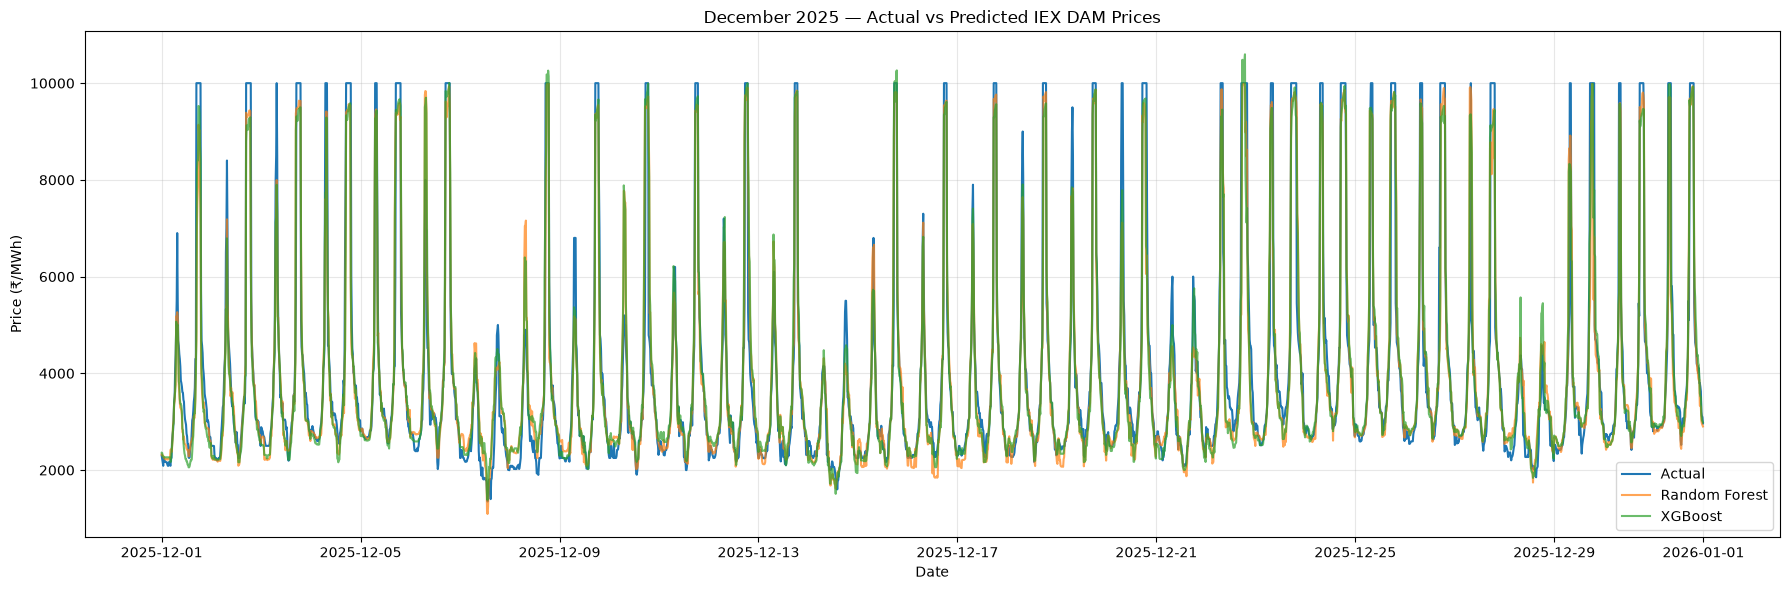

In [66]:
import matplotlib.pyplot as plt

predictions_df = pd.DataFrame({
    "timestamp": test_df["timestamp"].values,
    "Actual": y_test.values,
    "Previous Day": y_pred_previous_day.values,
    "Previous Week": y_pred_previous_week.values,
    "Random Forest": rf_predictions,
    "XGBoost": xgb_predictions
})

plt.figure(figsize=(18, 6))

plt.plot(
    predictions_df["timestamp"],
    predictions_df["Actual"],
    label="Actual",
    linewidth=1.5
)

# plt.plot(
#     predictions_df["timestamp"],
#     predictions_df["Previous Day"],
#     label="Previous Day",
#     alpha=0.7
# )

plt.plot(
    predictions_df["timestamp"],
    predictions_df["Random Forest"],
    label="Random Forest",
    alpha=0.7
)

plt.plot(
    predictions_df["timestamp"],
    predictions_df["XGBoost"],
    label="XGBoost",
    alpha=0.7
)

plt.title("December 2025 — Actual vs Predicted IEX DAM Prices")
plt.xlabel("Date")
plt.ylabel("Price (₹/MWh)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [67]:
hourly_df = predictions_df.copy()

hourly_df["hour"] = pd.to_datetime(
    hourly_df["timestamp"]
).dt.hour

hourly_results = []

for hour, group in hourly_df.groupby("hour"):

    hourly_results.append({
        "Hour": hour,
        "Previous Day MAE": mean_absolute_error(
            group["Actual"], group["Previous Day"]
        ),
        "Previous Week MAE": mean_absolute_error(
            group["Actual"], group["Previous Week"]
        ),
        "Random Forest MAE": mean_absolute_error(
            group["Actual"], group["Random Forest"]
        ),
        "XGBoost MAE": mean_absolute_error(
            group["Actual"], group["XGBoost"]
        )
    })

hourly_results_df = pd.DataFrame(hourly_results)

hourly_results_df.round(2)

,Hour,Previous Day MAE,Previous Week MAE,Random Forest MAE,XGBoost MAE
0,0,152.86,332.21,171.80,175.61
1,1,126.76,241.52,152.61,144.49
2,2,115.38,201.77,153.16,134.78
3,3,150.14,190.01,170.49,137.88
4,4,150.75,220.53,146.98,124.65
5,5,153.76,252.87,163.01,154.36
6,6,359.12,381.28,325.04,332.91
7,7,1528.25,2126.60,1143.30,1082.32
8,8,702.56,1096.42,578.71,611.20
9,9,473.36,641.45,358.32,322.20


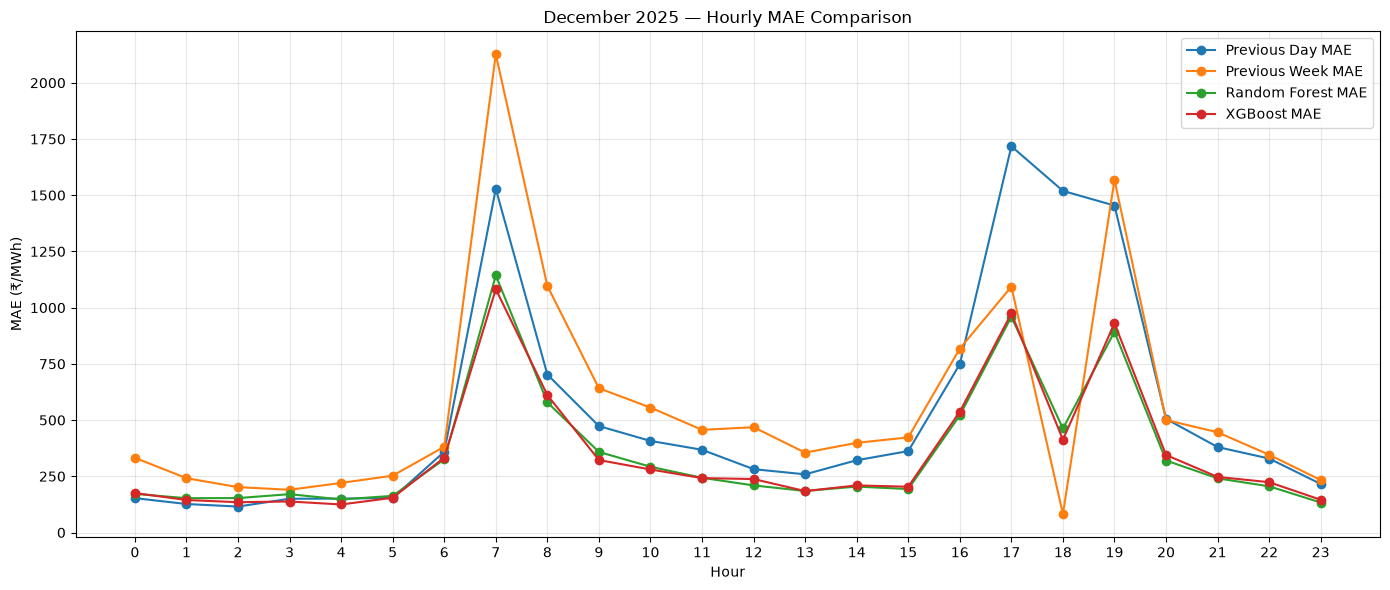

In [68]:
hourly_results_df.set_index("Hour").plot(
    figsize=(14, 6),
    marker="o"
)

plt.title("December 2025 — Hourly MAE Comparison")
plt.xlabel("Hour")
plt.ylabel("MAE (₹/MWh)")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [69]:
def categorize_price(price):
    if price < 4000:
        return "Normal"
    elif price < 8000:
        return "High"
    else:
        return "Very High"


predictions_df["Price Category"] = (
    predictions_df["Actual"].apply(categorize_price)
)

category_results = []

models = [
    "Previous Day",
    "Previous Week",
    "Random Forest",
    "XGBoost"
]

for category, group in predictions_df.groupby("Price Category"):

    for model in models:

        category_results.append({
            "Category": category,
            "Model": model,
            "Observations": len(group),
            "MAE": mean_absolute_error(
                group["Actual"], group[model]
            ),
            "RMSE": np.sqrt(mean_squared_error(
                group["Actual"], group[model]
            ))
        })

category_results_df = pd.DataFrame(category_results)

category_results_df.round(2)

,Category,Model,Observations,MAE,RMSE
0,High,Previous Day,581,961.80,1602.24
1,High,Previous Week,581,1038.85,1589.56
2,High,Random Forest,581,652.07,1028.79
3,High,XGBoost,581,665.90,1009.89
4,Normal,Previous Day,2105,317.35,626.29
5,Normal,Previous Week,2105,347.17,434.02
6,Normal,Random Forest,2105,200.56,265.90
7,Normal,XGBoost,2105,196.32,261.56
8,Very High,Previous Day,290,1234.99,2510.53
9,Very High,Previous Week,290,1140.75,2234.22


In [70]:
predictions_df.to_csv(
    "../data/processed/december_2025_predictions.csv",
    index=False
)


print("December final predictions csv exported.")

December final predictions csv exported.


In [71]:
models = [
    "Previous Day",
    "Previous Week",
    "Random Forest",
    "XGBoost"
]

updated_results = []

for model in models:
    updated_results.append({
        "Model": model,
        "MAE": mean_absolute_error(
            predictions_df["Actual"],
            predictions_df[model]
        ),
        "RMSE": np.sqrt(mean_squared_error(
            predictions_df["Actual"],
            predictions_df[model]
        )),
        "R2": r2_score(
            predictions_df["Actual"],
            predictions_df[model]
        )
    })

updated_results_df = pd.DataFrame(updated_results)

updated_results_df.sort_values("MAE").round(2)

,Model,MAE,RMSE,R2
3,XGBoost,349.73,623.45,0.92
2,Random Forest,351.09,650.77,0.91
0,Previous Day,532.58,1180.17,0.71
1,Previous Week,559.54,1054.96,0.77
